# Phase 2 - preprocessing pipeline and ablation (Part D)

**Question.** Which preparation steps help, and which hurt?

**Brief and report.** Part D. Report Section 4.3 and Tables 6–7. Training CV only.

The setup cell below makes the repository root the working folder, so `src/` can be imported, and defines two helpers: `results(name)` reads a table from `results/` and `show(...)` displays saved figures from `reports/figures/`.

In [1]:
import os, sys
from pathlib import Path
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import Image, Markdown, display
from src.common import ROOT
pd.set_option('display.precision', 3)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

def show(*names):
    """Display saved figures from reports/figures/."""
    for name in names:
        display(Markdown(f'**reports/figures/{name}**'))
        display(Image(filename=str(ROOT / 'reports' / 'figures' / name)))

def results(name):
    return pd.read_csv(ROOT / 'results' / name)

### 1. Ablation: change one step at a time
`run_ablation()` in `src/preprocess.py` starts from the reference pipeline built by `build_pipeline()`:
- impute numbers with the median plus a missing flag, and give categories a "Missing" level
- add four engineered fields
- one-hot encode the categories
- scale the numbers
- drop constant columns

Each variant changes one step: no scaling, no engineered fields, feature selection, PCA, SMOTE, class weights, ordinal encoding, zero imputation or duplicate weighting. Every variant is scored with logistic regression and gradient boosting on the same five group-aware folds. Every step sits inside the pipeline, so each fold learns it from its own training rows only.

**How to read the table.** `delta_pr_auc_vs_reference` is the change in CV AP; a negative value means the variant hurt.

In [2]:
from src.preprocess import run_ablation
ablation = run_ablation()
display(ablation[['model', 'configuration', 'pr_auc_mean', 'pr_auc_std', 'delta_pr_auc_vs_reference', 'f1_mean', 'recall_mean', 'fit_seconds']])

Phase 2 | ablation: Logistic Regression, reference: AP 0.628


Phase 2 | ablation: Logistic Regression, no_scaling: AP 0.628


Phase 2 | ablation: Logistic Regression, no_engineering: AP 0.611


Phase 2 | ablation: Logistic Regression, feature_selection: AP 0.626


Phase 2 | ablation: Logistic Regression, pca_95pct: AP 0.607


Phase 2 | ablation: Logistic Regression, smote: AP 0.626


... (12 outputs left out)

Phase 2 | ablation: Hist Gradient Boosting, constant_numeric_imputation: AP 0.675


Phase 2 | ablation: Hist Gradient Boosting, restore_duplicate_frequency: AP 0.665


Phase 2 | pipeline decision: Selected reference: {'scale': True, 'engineer': True, 'selection': False, 'pca': False, 'sampling': 'none', 'encoding': 'onehot', 'numeric_imputation': 'median'}


,model,configuration,pr_auc_mean,pr_auc_std,delta_pr_auc_vs_reference,f1_mean,recall_mean,fit_seconds
0,Logistic Regression,reference,0.628,0.005,0.000e+00,0.522,0.417,3.871
1,Logistic Regression,no_scaling,0.628,0.005,-1.418e-04,0.521,0.417,3.716
2,Logistic Regression,no_engineering,0.611,0.006,-1.727e-02,0.512,0.408,3.359
3,Logistic Regression,feature_selection,0.626,0.005,-2.301e-03,0.518,0.413,3.688
4,Logistic Regression,pca_95pct,0.607,0.006,-2.050e-02,0.481,0.366,4.016
5,Logistic Regression,smote,0.626,0.006,-1.882e-03,0.578,0.709,9.799
6,Logistic Regression,class_weight,0.625,0.006,-2.663e-03,0.579,0.717,3.466
7,Logistic Regression,ordinal_encoding,0.558,0.007,-6.950e-02,0.360,0.245,2.021
8,Logistic Regression,constant_numeric_imputation,0.628,0.005,-4.277e-07,0.522,0.417,3.437
9,Logistic Regression,restore_duplicate_frequency,0.608,0.009,-2.033e-02,0.548,0.489,3.676


### 2. The selection rule
A variant is adopted only if it improves CV AP by at least 0.001 for both models, so one pipeline can serve all three model families. The JSON shows the chosen configuration and the rule; the chart shows every variant's change.

{'configuration': 'reference',
 'options': {'scale': True,
  'engineer': True,
  'selection': False,
  'pca': False,
  'sampling': 'none',
  'encoding': 'onehot',
  'numeric_imputation': 'median'},
 'metric': 'average_precision',
 'selection_rule': 'keep the reference unless an option gains >= 0.001 training-CV AP for both reference models; duplicate weighting is a sensitivity check, never selected',
 'cv_rows': 69877,
 'folds': 5,
 'reference_pr_auc': {'Logistic Regression': 0.6279760566327452,
  'Hist Gradient Boosting': 0.6758574172909008}}

**reports/figures/fig_D_01_ablation.png**

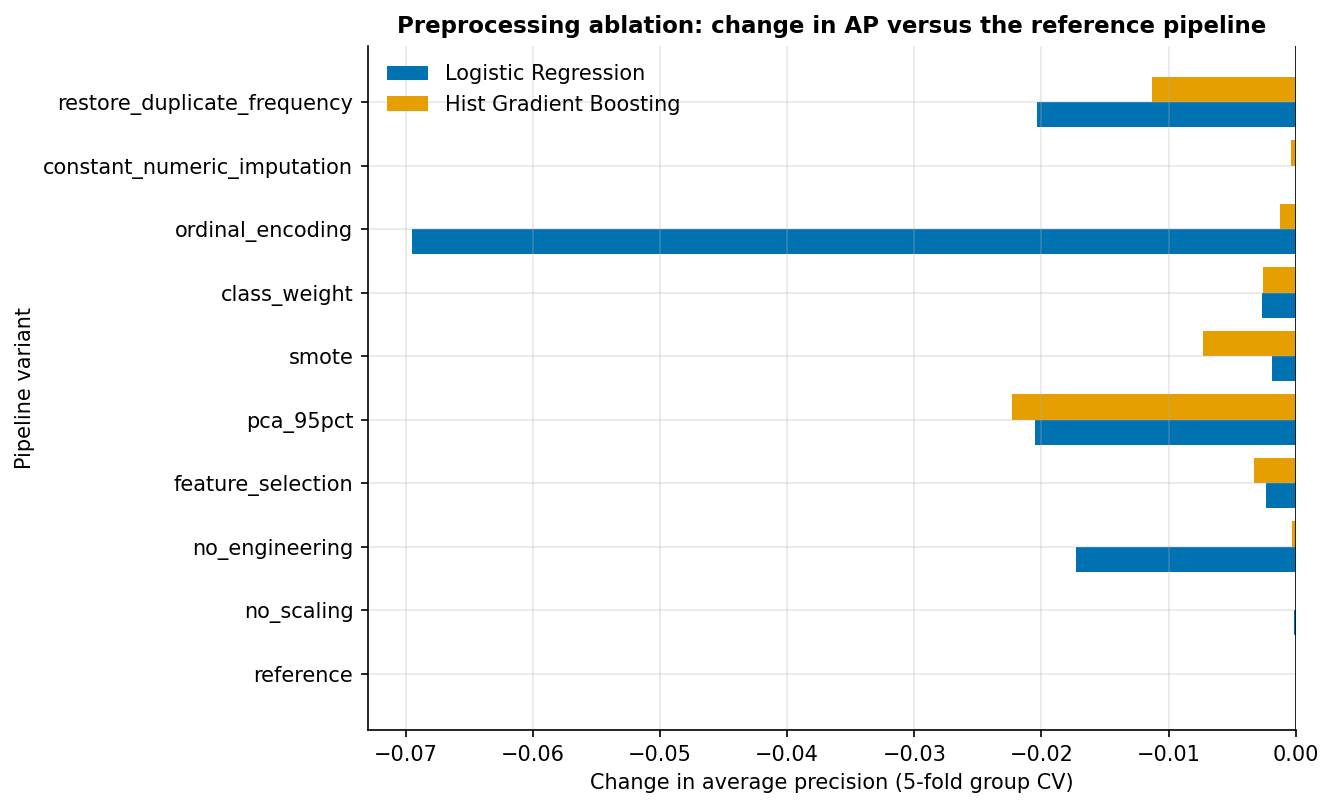

In [3]:
import json
display(json.loads((ROOT / 'results/phase2_selected_pipeline.json').read_text(encoding='utf-8')))
show('fig_D_01_ablation.png')

### Long tails: capping and log transforms (added 13 November 2026, decision D15)
`extreme_value_check()` in `src/preprocess.py` inserts `ExtremeValues` after the engineered fields. It learns, on each training fold only, the 1st and 99th percentiles (for capping) and which fields have skewness above 1 (for `log(1 + x)`). Logistic regression and boosting are compared with the reference pipeline on the same ten repeated folds as notebook 06, with corrected paired intervals and a Holm adjustment. This was run after the final evaluation, so the recommended model is not changed whatever the result.

**How to read the output.** The first table gives each configuration's mean AP over ten folds. In the second, `mean` is the change against the reference and `p_holm` the adjusted p-value: a log transform helps logistic regression, while boosting is unaffected because trees split on the order of values.

In [4]:
from src.preprocess import extreme_value_check
extreme_summary, extreme_comparisons = extreme_value_check()
display(extreme_summary)
display(extreme_comparisons)

D15 | extreme values: Logistic Regression, reference: CV AP 0.6279


D15 | extreme values: Logistic Regression, cap at 1st/99th percentile: CV AP 0.6281


D15 | extreme values: Logistic Regression, log transform of skewed fields: CV AP 0.6418


D15 | extreme values: Logistic Regression, cap and log: CV AP 0.6400


D15 | extreme values: Hist Gradient Boosting, reference: CV AP 0.6753


D15 | extreme values: Hist Gradient Boosting, cap at 1st/99th percentile: CV AP 0.6749


D15 | extreme values: Hist Gradient Boosting, log transform of skewed fields: CV AP 0.6753


D15 | extreme values: Hist Gradient Boosting, cap and log: CV AP 0.6749


,model,configuration,mean,std
0,Logistic Regression,reference,0.628,0.005
1,Logistic Regression,cap at 1st/99th percentile,0.628,0.005
2,Logistic Regression,log transform of skewed fields,0.642,0.005
3,Logistic Regression,cap and log,0.640,0.006
4,Hist Gradient Boosting,reference,0.675,0.005
5,Hist Gradient Boosting,cap at 1st/99th percentile,0.675,0.006
6,Hist Gradient Boosting,log transform of skewed fields,0.675,0.005
7,Hist Gradient Boosting,cap and log,0.675,0.006


,model,option,reference,mean,sd,ci_low,ci_high,p_value,n,validation_train_ratio,p_holm
0,Logistic Regression,cap at 1st/99th percentile,reference,1.512e-04,1.453e-03,-0.002,2.096e-03,8.643e-01,10,0.25,1.000e+00
1,Logistic Regression,log transform of skewed fields,reference,1.387e-02,2.370e-03,0.011,1.704e-02,3.919e-06,10,0.25,2.352e-05
2,Logistic Regression,cap and log,reference,1.212e-02,2.324e-03,0.009,1.523e-02,1.012e-05,10,0.25,5.062e-05
3,Hist Gradient Boosting,cap at 1st/99th percentile,reference,-3.471e-04,7.427e-04,-0.001,6.469e-04,4.499e-01,10,0.25,1.000e+00
4,Hist Gradient Boosting,log transform of skewed fields,reference,0.000e+00,0.000e+00,0.000,0.000e+00,1.000e+00,10,0.25,1.000e+00
5,Hist Gradient Boosting,cap and log,reference,-3.471e-04,7.427e-04,-0.001,6.469e-04,4.499e-01,10,0.25,1.000e+00
